In [12]:
!pip install -q "transformers==4.49.0" tf-keras tensorflow-datasets importlib_resources scikit-learn matplotlib pandas

In [13]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from transformers import TFViTForImageClassification

tf.keras.utils.set_random_seed(42)

IMG_SIZE = 224
NUM_CLASSES = 37
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [14]:
# Load dataset without converting the full dataset to NumPy
train_all = tfds.load(
    "oxford_iiit_pet",
    split="train",
    as_supervised=True
)

test_raw = tfds.load(
    "oxford_iiit_pet",
    split="test",
    as_supervised=True
)

# Create a reproducible training/validation split
train_all = train_all.shuffle(
    3680,
    seed=42,
    reshuffle_each_iteration=False
)

val_raw = train_all.take(368)
train_raw = train_all.skip(368)

# Resize one image at a time
def resize_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)

train_raw = train_raw.map(
    resize_image, num_parallel_calls=AUTOTUNE
)
val_raw = val_raw.map(
    resize_image, num_parallel_calls=AUTOTUNE
)
test_raw = test_raw.map(
    resize_image, num_parallel_calls=AUTOTUNE
)

# MobileNetV2 input preprocessing: scale pixels to [-1, 1]
def prepare_cnn(image, label):
    image = image / 127.5 - 1.0
    return image, label

cnn_train = train_raw.map(
    prepare_cnn, num_parallel_calls=AUTOTUNE
).batch(BATCH_SIZE).prefetch(1)

cnn_val = val_raw.map(
    prepare_cnn, num_parallel_calls=AUTOTUNE
).batch(BATCH_SIZE).prefetch(1)

cnn_test = test_raw.map(
    prepare_cnn, num_parallel_calls=AUTOTUNE
).batch(BATCH_SIZE).prefetch(1)

# Class names
class_names = tfds.builder("oxford_iiit_pet").info.features[
    "label"
].names

print("Classes:", len(class_names))
print("Training pipeline ready.")

Classes: 37
Training pipeline ready.


In [15]:
base_cnn = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_cnn.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)

# The dataset is already scaled to [-1, 1]
x = base_cnn(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES, activation="softmax"
)(x)

cnn = models.Model(inputs, outputs)

cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_start = time.time()

# Stage 1: Train the classifier
history_head = cnn.fit(
    cnn_train,
    validation_data=cnn_val,
    epochs=8,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=3,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            patience=2,
            factor=0.2
        )
    ],
    verbose=1
)

# Stage 2: Fine-tune the last layers
base_cnn.trainable = True

for layer in base_cnn.layers[:-30]:
    layer.trainable = False

for layer in base_cnn.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = cnn.fit(
    cnn_train,
    validation_data=cnn_val,
    epochs=5,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

cnn_training_time = time.time() - cnn_start

cnn_loss, cnn_accuracy = cnn.evaluate(cnn_test, verbose=1)

print("CNN Test Accuracy:", round(float(cnn_accuracy), 4))
print("CNN Training Time:", round(cnn_training_time, 2), "seconds")

Epoch 1/8
207/207 [==============================] - 26s 73ms/step - loss: 1.2105 - accuracy: 0.6639 - val_loss: 0.3974 - val_accuracy: 0.8913 - lr: 0.0010
Epoch 2/8
207/207 [==============================] - 22s 68ms/step - loss: 0.4614 - accuracy: 0.8514 - val_loss: 0.3396 - val_accuracy: 0.8940 - lr: 0.0010
Epoch 3/8
207/207 [==============================] - 20s 63ms/step - loss: 0.3494 - accuracy: 0.8780 - val_loss: 0.3312 - val_accuracy: 0.9022 - lr: 0.0010
Epoch 4/8
207/207 [==============================] - 24s 77ms/step - loss: 0.3007 - accuracy: 0.9019 - val_loss: 0.3024 - val_accuracy: 0.9158 - lr: 0.0010
Epoch 5/8
207/207 [==============================] - 22s 70ms/step - loss: 0.2216 - accuracy: 0.9212 - val_loss: 0.3039 - val_accuracy: 0.9076 - lr: 0.0010
Epoch 6/8
207/207 [==============================] - 24s 77ms/step - loss: 0.2205 - accuracy: 0.9230 - val_loss: 0.3333 - val_accuracy: 0.8995 - lr: 0.0010
Epoch 7/8
207/207 [==============================] - 20s 65ms/st

In [16]:
model_name = "google/vit-base-patch16-224"

vit = TFViTForImageClassification.from_pretrained(
    model_name,
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True
)

# ViT pretrained processor uses mean=0.5 and std=0.5
def prepare_vit(image, label):
    image = image / 255.0
    image = (image - 0.5) / 0.5

    # Convert HWC to CHW for Hugging Face TensorFlow ViT
    image = tf.transpose(image, [2, 0, 1])

    return {"pixel_values": image}, label


VIT_BATCH_SIZE = 4

vit_train = train_raw.map(
    prepare_vit, num_parallel_calls=2
).batch(VIT_BATCH_SIZE).prefetch(1)

vit_val = val_raw.map(
    prepare_vit, num_parallel_calls=2
).batch(VIT_BATCH_SIZE).prefetch(1)

vit_test = test_raw.map(
    prepare_vit, num_parallel_calls=2
).batch(VIT_BATCH_SIZE).prefetch(1)

vit.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

vit_start = time.time()

vit_history = vit.fit(
    vit_train,
    validation_data=vit_val,
    epochs=5,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=2,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            patience=1,
            factor=0.2
        )
    ],
    verbose=1
)

vit_training_time = time.time() - vit_start

vit_loss, vit_accuracy = vit.evaluate(vit_test, verbose=1)

print("ViT Test Accuracy:", round(float(vit_accuracy), 4))
print("ViT Training Time:", round(vit_training_time, 2), "seconds")

Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFViTForImageClassification: ['classifier.weight', 'classifier.bias']
- This IS expected if you are initializing TFViTForImageClassification from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFViTForImageClassification from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
All the weights of TFViTForImageClassification were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFViTForImageClassification for predictions without further training.
Some weights of TFViTForImageClassification were not initialized from the model checkpoint are newly initialize

Epoch 1/5
828/828 [==============================] - 228s 219ms/step - loss: 1.4491 - accuracy: 0.7551 - val_loss: 0.4765 - val_accuracy: 0.9212 - lr: 2.0000e-05
Epoch 2/5
828/828 [==============================] - 187s 216ms/step - loss: 0.1800 - accuracy: 0.9771 - val_loss: 0.3044 - val_accuracy: 0.9293 - lr: 2.0000e-05
Epoch 3/5
828/828 [==============================] - 188s 218ms/step - loss: 0.0449 - accuracy: 0.9982 - val_loss: 0.2523 - val_accuracy: 0.9266 - lr: 2.0000e-05
Epoch 4/5
918/918 [==============================] - 73s 79ms/step - loss: 0.3388 - accuracy: 0.9111
ViT Test Accuracy: 0.9111
ViT Training Time: 791.77 seconds


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def get_predictions(model, dataset, is_vit=False):
    true_labels = []
    predicted_labels = []

    for features, labels in dataset:
        if is_vit:
            output = model(
                pixel_values=features["pixel_values"],
                training=False
            )
            logits = output.logits
        else:
            logits = model(features, training=False)

        predictions = tf.argmax(
            logits, axis=1
        ).numpy()

        true_labels.extend(labels.numpy().tolist())
        predicted_labels.extend(predictions.tolist())

    return np.array(true_labels), np.array(predicted_labels)


y_true_cnn, cnn_predictions = get_predictions(
    cnn, cnn_test, is_vit=False
)

y_true_vit, vit_predictions = get_predictions(
    vit, vit_test, is_vit=True
)

def calculate_metrics(y_true, predictions):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions,
            average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions,
            average="weighted", zero_division=0
        )
    }

cnn_metrics = calculate_metrics(y_true_cnn, cnn_predictions)
vit_metrics = calculate_metrics(y_true_vit, vit_predictions)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Loss",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score",
        "Training Time (seconds)"
    ],
    "CNN (MobileNetV2)": [
        cnn_metrics["Accuracy"],
        cnn_loss,
        cnn_metrics["Precision"],
        cnn_metrics["Recall"],
        cnn_metrics["F1-Score"],
        cnn_training_time
    ],
    "Vision Transformer": [
        vit_metrics["Accuracy"],
        vit_loss,
        vit_metrics["Precision"],
        vit_metrics["Recall"],
        vit_metrics["F1-Score"],
        vit_training_time
    ]
})

display(results.round(4))

print("\nCNN Classification Report")
print(classification_report(
    y_true_cnn,
    cnn_predictions,
    target_names=class_names,
    zero_division=0
))

print("\nViT Classification Report")
print(classification_report(
    y_true_vit,
    vit_predictions,
    target_names=class_names,
    zero_division=0
))

,Metric,CNN (MobileNetV2),Vision Transformer
0,Accuracy,0.8926,0.9193
1,Loss,0.3788,0.3003
2,Weighted Precision,0.9000,0.9262
3,Weighted Recall,0.8926,0.9193
4,Weighted F1-Score,0.8929,0.9176
5,Training Time (seconds),372.6084,802.4345



CNN Classification Report
                            precision    recall  f1-score   support

                Abyssinian       0.95      0.76      0.84        98
          american_bulldog       0.70      0.90      0.79       100
 american_pit_bull_terrier       0.84      0.54      0.66       100
              basset_hound       0.95      0.95      0.95       100
                    beagle       0.95      0.89      0.92       100
                    Bengal       0.75      0.77      0.76       100
                    Birman       0.73      0.86      0.79       100
                    Bombay       0.88      0.89      0.88        88
                     boxer       0.89      0.91      0.90        99
         British_Shorthair       0.82      0.80      0.81       100
                 chihuahua       0.86      0.90      0.88       100
              Egyptian_Mau       0.91      0.81      0.86        97
    english_cocker_spaniel       0.98      0.94      0.96       100
            english_

/tmp/ipykernel_1342/1848150643.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


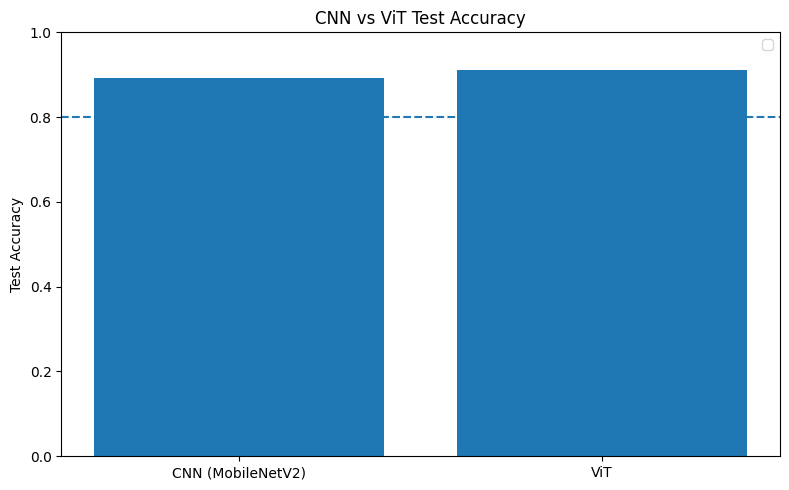

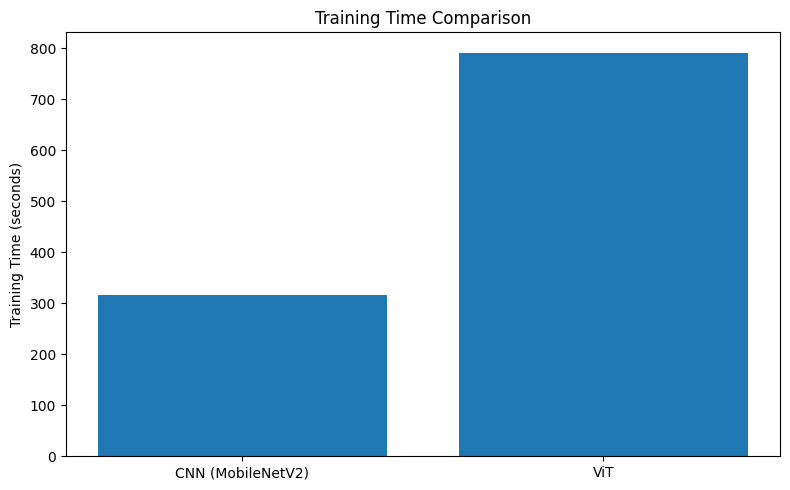

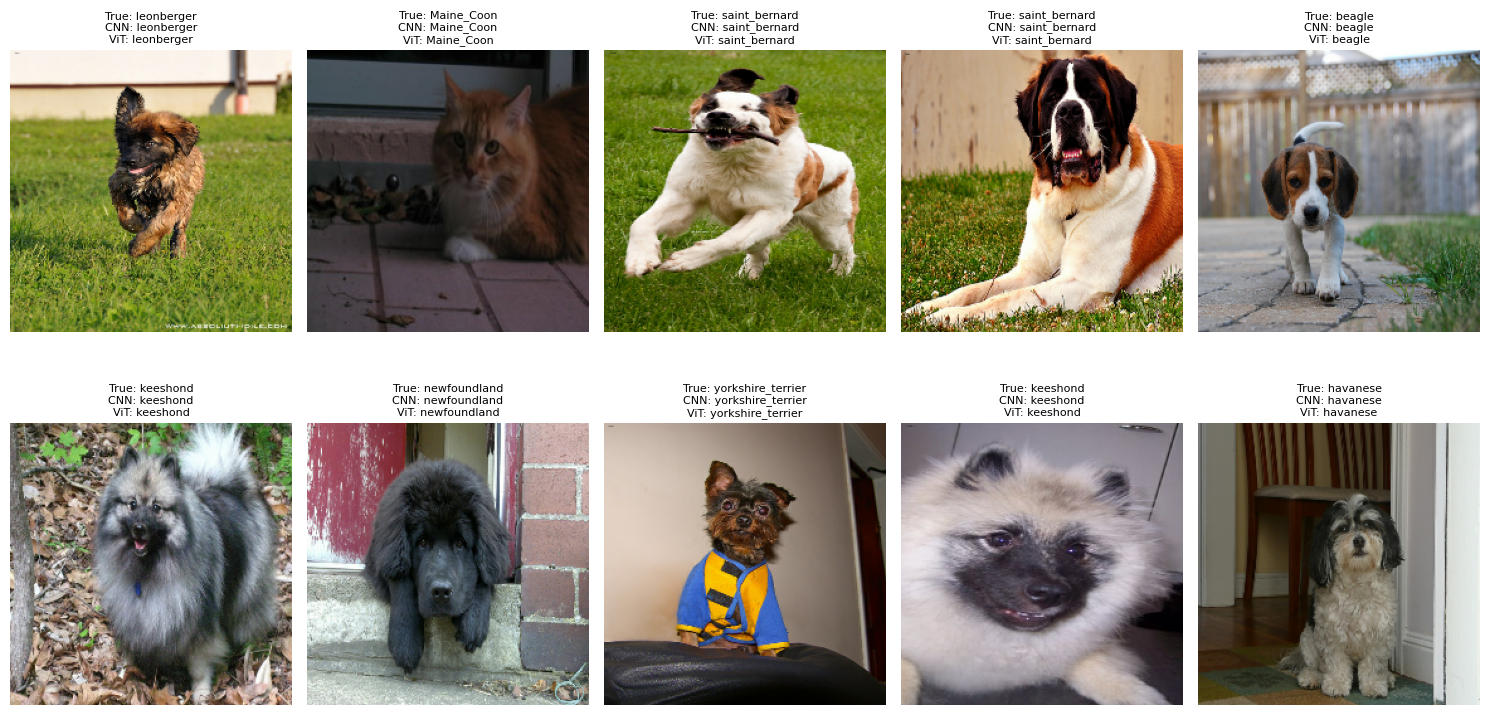


--- Accuracy  ---
CNN accuracy: 89.32%
ViT accuracy: 91.11%


In [18]:
# Test accuracy comparison
plt.figure(figsize=(8, 5))
plt.bar(
    ["CNN (MobileNetV2)", "ViT"],
    [cnn_accuracy, vit_accuracy]
)
plt.axhline(0.80, linestyle="--")
plt.ylim(0, 1)
plt.ylabel("Test Accuracy")
plt.title("CNN vs ViT Test Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Training time
plt.figure(figsize=(8, 5))
plt.bar(
    ["CNN (MobileNetV2)", "ViT"],
    [cnn_training_time, vit_training_time]
)
plt.ylabel("Training Time (seconds)")
plt.title("Training Time Comparison")
plt.tight_layout()
plt.show()

# Sample predictions streamed from the test dataset
sample_images = []
sample_labels = []

for images, labels in test_raw.batch(10).take(1):
    sample_images = images.numpy()
    sample_labels = labels.numpy()

# Get predictions for these 10 samples
sample_cnn = cnn.predict(
    sample_images / 127.5 - 1.0,
    verbose=0
)
sample_cnn = np.argmax(sample_cnn, axis=1)

sample_vit_inputs = tf.map_fn(
    lambda img: tf.transpose(
        (img / 255.0 - 0.5) / 0.5,
        [2, 0, 1]
    ),
    tf.cast(sample_images, tf.float32),
    fn_output_signature=tf.TensorSpec(
        shape=(3, IMG_SIZE, IMG_SIZE),
        dtype=tf.float32
    )
)

sample_vit_output = vit(
    pixel_values=sample_vit_inputs,
    training=False
)

sample_vit = tf.argmax(
    sample_vit_output.logits, axis=1
).numpy()

plt.figure(figsize=(15, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(sample_images[i].astype("uint8"))
    plt.title(
        f"True: {class_names[sample_labels[i]]}\n"
        f"CNN: {class_names[sample_cnn[i]]}\n"
        f"ViT: {class_names[sample_vit[i]]}",
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

print("\n--- Accuracy  ---")
print(f"CNN accuracy: {cnn_accuracy:.2%}")
print(f"ViT accuracy: {vit_accuracy:.2%}")